<a href="https://colab.research.google.com/github/challapoojitha207-blip/DEEP-LEARNING/blob/main/SKILL/Skill1dl.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install -q fastapi uvicorn nest-asyncio requests python-multipart

In [2]:
import torch

if torch.cuda.is_available():
    device = torch.device("cuda")
    print("GPU Available:", torch.cuda.get_device_name(0))
else:
    device = torch.device("cpu")
    print("GPU not available. Using CPU.")

print("Selected Device:", device)

GPU not available. Using CPU.
Selected Device: cpu


In [3]:
import torch
from torchvision import models
from PIL import Image

weights = models.MobileNet_V2_Weights.DEFAULT

model = models.mobilenet_v2(weights=weights)

model = model.to(device)

model.eval()

preprocess = weights.transforms()

print("AI Model Loaded Successfully!")
print("Model: MobileNetV2")
print("Device:", device)

Downloading: "https://download.pytorch.org/models/mobilenet_v2-7ebf99e0.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v2-7ebf99e0.pth


100%|██████████| 13.6M/13.6M [00:00<00:00, 106MB/s] 

AI Model Loaded Successfully!
Model: MobileNetV2
Device: cpu


In [4]:
def predict_image(image):

    image = image.convert("RGB")

    image_tensor = preprocess(image)

    image_tensor = image_tensor.unsqueeze(0)

    image_tensor = image_tensor.to(device)

    with torch.no_grad():
        output = model(image_tensor)

    probabilities = torch.nn.functional.softmax(
        output[0], dim=0
    )

    confidence, predicted_class = torch.max(
        probabilities, dim=0
    )

    class_name = weights.meta["categories"][
        predicted_class.item()
    ]

    return {
        "prediction": class_name,
        "confidence": round(confidence.item() * 100, 2)
    }

print("Prediction Function Ready!")

Prediction Function Ready!


Saving DOG.png to DOG.png


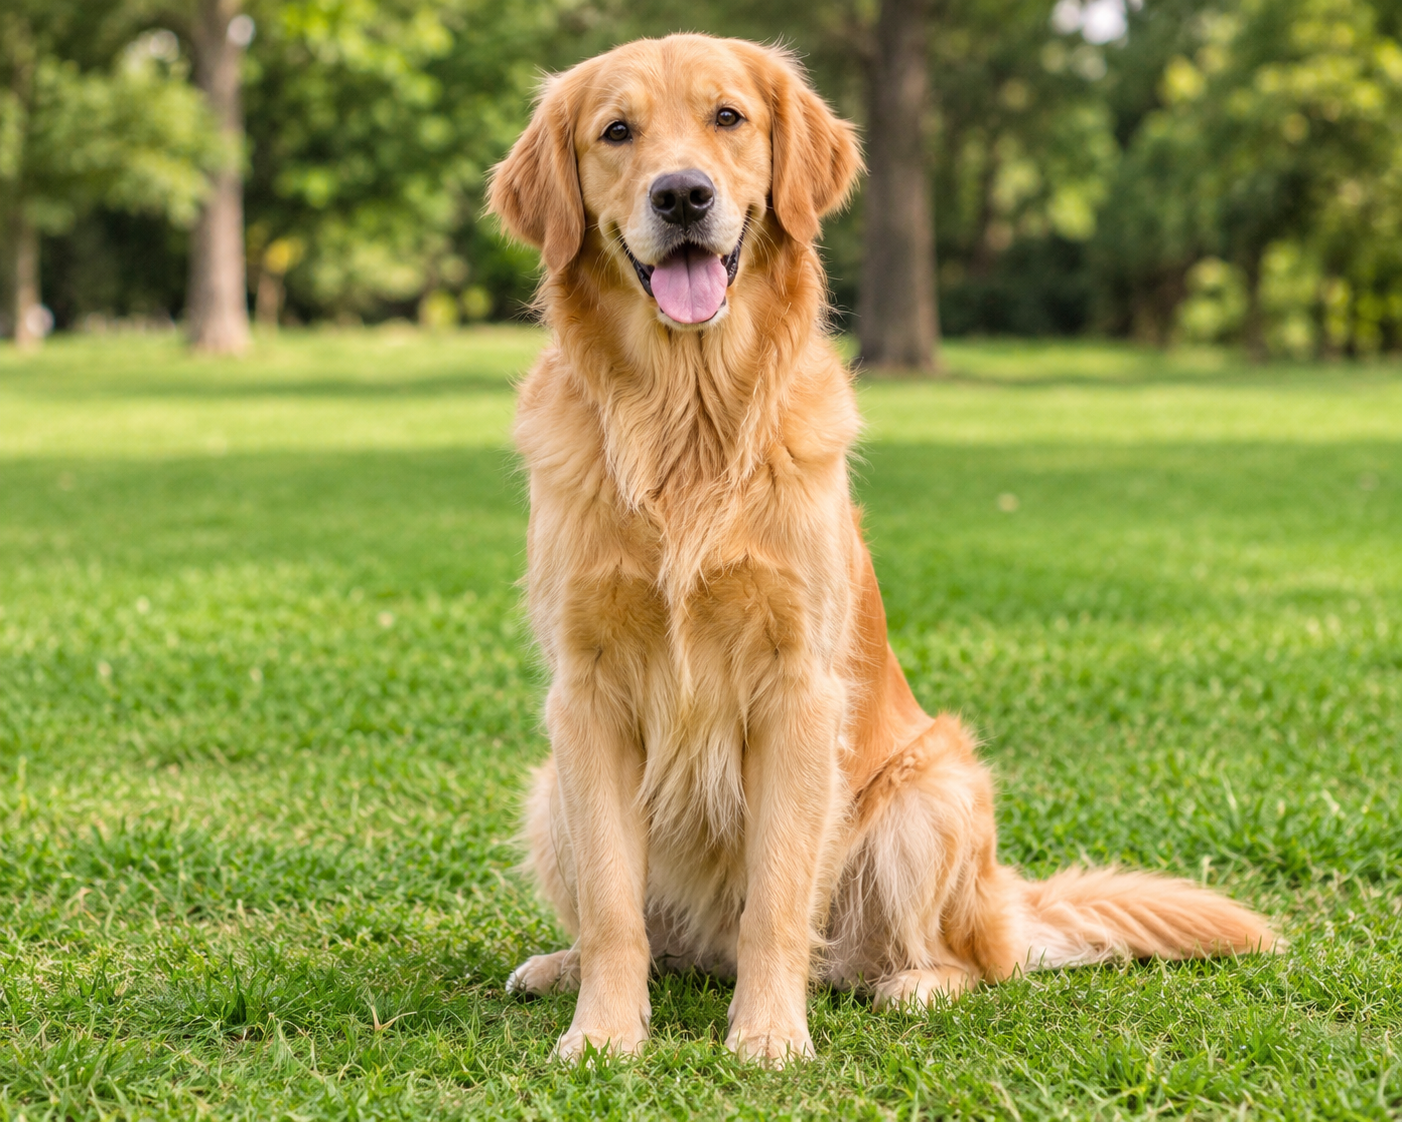

Prediction: golden retriever
Confidence: 33.9 %


In [5]:
from google.colab import files

uploaded = files.upload()

filename = next(iter(uploaded))

image = Image.open(filename)

display(image)

result = predict_image(image)

print("Prediction:", result["prediction"])
print("Confidence:", result["confidence"], "%")

In [6]:
from fastapi import FastAPI, UploadFile, File
from PIL import Image
import io

app = FastAPI(
    title="VisionPort AI",
    description="Image Classification API",
    version="1.0"
)

@app.get("/")
def home():
    return {
        "message": "Welcome to VisionPort AI",
        "status": "Running"
    }

@app.post("/predict")
async def predict(file: UploadFile = File(...)):

    image_bytes = await file.read()

    image = Image.open(
        io.BytesIO(image_bytes)
    )

    result = predict_image(image)

    return {
        "filename": file.filename,
        "prediction": result["prediction"],
        "confidence": result["confidence"]
    }

print("FastAPI Application Created!")

FastAPI Application Created!


In [7]:
import nest_asyncio
import uvicorn
import threading
import time

nest_asyncio.apply()

def start_server():
    uvicorn.run(
        app,
        host="0.0.0.0",
        port=8000,
        log_level="warning"
    )

server_thread = threading.Thread(
    target=start_server,
    daemon=True
)

server_thread.start()

time.sleep(3)

print("VisionPort Server Started!")

VisionPort Server Started!


In [8]:
import nest_asyncio
import uvicorn
import threading
import time

nest_asyncio.apply()

def start_server():
    uvicorn.run(
        app,
        host="0.0.0.0",
        port=8000,
        log_level="warning"
    )

server_thread = threading.Thread(
    target=start_server,
    daemon=True
)

server_thread.start()

time.sleep(3)

print("VisionPort Server Started!")

ERROR:    [Errno 98] error while attempting to bind on address ('0.0.0.0', 8000): address already in use


VisionPort Server Started!


In [9]:
import requests

url = "http://127.0.0.1:8000/"

response = requests.get(url)

print("Status Code:", response.status_code)
print("Response:", response.json())

Status Code: 200
Response: {'message': 'Welcome to VisionPort AI', 'status': 'Running'}


In [10]:
url = "http://127.0.0.1:8000/predict"

with open(filename, "rb") as image_file:

    response = requests.post(
        url,
        files={
            "file": (
                filename,
                image_file,
                "image/jpeg"
            )
        }
    )

print("Status Code:", response.status_code)
print("API Response:")
print(response.json())

Status Code: 200
API Response:
{'filename': 'DOG.png', 'prediction': 'golden retriever', 'confidence': 33.9}
